B = 0.1500  1-B = 0.8500  Tdom = 208.152
window: 0.400 < w < 1.400  (w = 0.8)
IL=1.3  BL=0.1500 BR=0.1500  TL=208.152 TR=208.152  fracL=0.5000
IL=1.45  BL=0.2250 BR=0.1500  TL=197.067 TR=159.496  fracL=0.5527
IL=1.6  BL=0.3000 BR=0.1500  TL=184.853 TR=124.974  fracL=0.5966

(i) hand-overs: [  95.9   251.88  462.96  671.06  878.65 1086.16]
(i) mean T = 207.499 (n = 14, std = 0.027)
(i) a_L range, t > 1500: 0.1527 to 0.8489

(ii) IL   TL_sim  TL_th    diff   TR_sim  TR_th    diff   fracL_sim fracL_th  nL nR
     1.3   207.505 208.152  -0.647  207.493 208.152  -0.659    0.5000   0.5000  7 7
     1.45  197.141 197.067  +0.074  160.087 159.496  +0.591    0.5519   0.5527  8 7
     1.6   186.127 184.853  +1.273  126.590 124.974  +1.616    0.5952   0.5966  9 9

(iii) w = 0.3: mean T = 166.298 (n = 18, std = 0.361), theory = 166.355, diff = -0.057 (-0.03%)


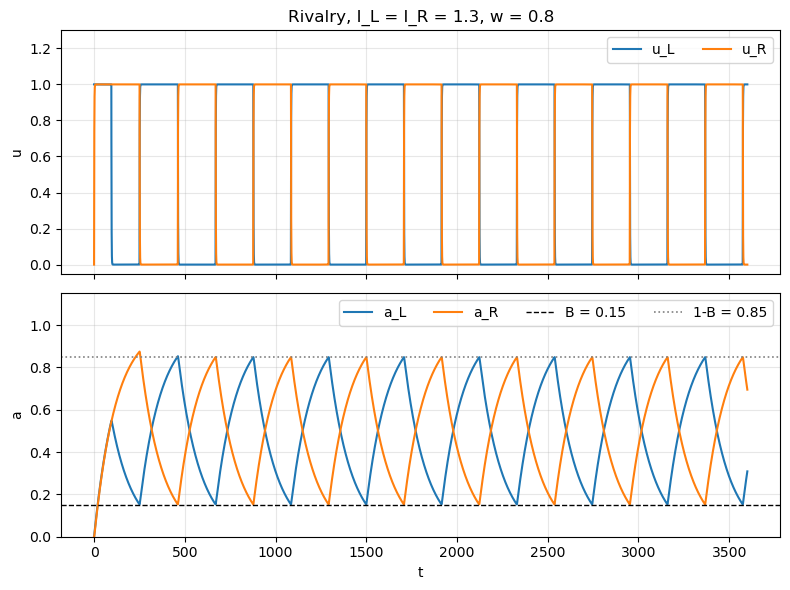

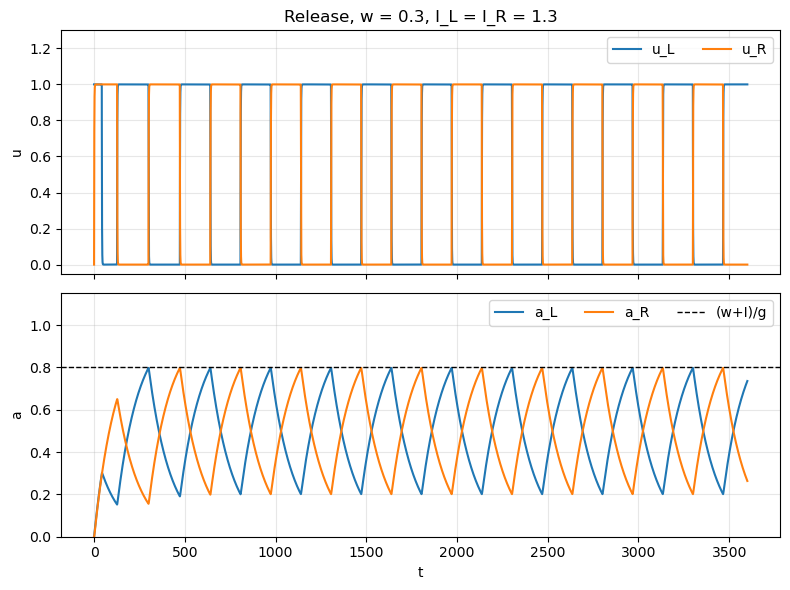

In [2]:
# APPM 4370/5370 HW5, Problem 2: binocular rivalry with slow adaptation.
%matplotlib inline

import numpy as np
from scipy.integrate import solve_ivp
from scipy.special import expit
import matplotlib.pyplot as plt

plt.close("all")

# Parameters
w0, beta, g, tau_a, eta = 0.8, 1.0, 2.0, 120.0, 1000.0
TEND = 30 * tau_a
DT = 0.005          


def rhs_factory(w, IL, IR):
    def rhs(t, y):
        uL, uR, aL, aR = y
        return [-uL + expit(eta * (w*uL - beta*uR - g*aL + IL)),
                -uR + expit(eta * (w*uR - beta*uL - g*aR + IR)),
                (-aL + uL) / tau_a,
                (-aR + uR) / tau_a]
    return rhs


def simulate(IL, IR, w=w0):
    t = np.arange(0.0, TEND + DT, DT)
    s = solve_ivp(rhs_factory(w, IL, IR), [0, TEND], [1.0, 0.0, 0.0, 0.0],
                  method="Radau", t_eval=t, rtol=1e-9, atol=1e-11)
    return s.t, s.y


def dominance_durations(t, uL, uR, discard=3):
    d = uL - uR
    cur = 1 if d[0] > 0.5 else (-1 if d[0] < -0.5 else 0)
    label = np.empty(len(t), dtype=int)
    for i in range(len(t)):
        if d[i] > 0.5:
            cur = 1
        elif d[i] < -0.5:
            cur = -1
        label[i] = cur
    times, new = [], []
    for i in np.where(np.diff(label) != 0)[0]:
        target = 0.5 if label[i+1] == 1 else -0.5
        times.append(t[i] + (target - d[i]) / (d[i+1] - d[i]) * (t[i+1] - t[i]))
        new.append(label[i+1])
    times, new = np.array(times), np.array(new)
    return np.diff(times)[discard:], new[:-1][discard:], times


def theory_sym(I, w=w0):
    B = (I - beta) / g
    return B, tau_a * np.log((1 - B) / B)


def theory_asym(IL, IR):
    BL, BR = (IL - beta) / g, (IR - beta) / g
    return BL, BR, tau_a*np.log((1 - BL)/BR), tau_a*np.log((1 - BR)/BL)


# theory numbers
I = 1.3
B, Tdom = theory_sym(I)
print(f"B = {B:.4f}  1-B = {1-B:.4f}  Tdom = {Tdom:.3f}")
print(f"window: {g+beta-2*I:.3f} < w < {g+2*beta-2*I:.3f}  (w = {w0})")
for IL in (1.3, 1.45, 1.6):
    BL, BR, TL, TR = theory_asym(IL, 1.3)
    print(f"IL={IL}  BL={BL:.4f} BR={BR:.4f}  TL={TL:.3f} TR={TR:.3f}  fracL={TL/(TL+TR):.4f}")

#  (i) symmetric input, I = 1.3
t, y = simulate(1.3, 1.3)
durs, labs, hand = dominance_durations(t, y[0], y[1])
print(f"\n(i) hand-overs: {np.round(hand[:6], 2)}")
print(f"(i) mean T = {durs.mean():.3f} (n = {len(durs)}, std = {durs.std():.3f})")
print(f"(i) a_L range, t > 1500: {y[2][t > 1500].min():.4f} to {y[2][t > 1500].max():.4f}")

# figure 1 of 2: (i)
fig1, ax = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
ax[0].plot(t, y[0], label="u_L")
ax[0].plot(t, y[1], label="u_R")
ax[0].set_ylabel("u")
ax[0].set_ylim(-0.05, 1.3)
ax[0].set_title("Rivalry, I_L = I_R = 1.3, w = 0.8")
ax[0].legend(ncol=2)
ax[0].grid(alpha=0.3)
ax[1].plot(t, y[2], label="a_L")
ax[1].plot(t, y[3], label="a_R")
ax[1].axhline(B, color="k", ls="--", lw=1, label=f"B = {B:.2f}")
ax[1].axhline(1 - B, color="gray", ls=":", lw=1.2, label=f"1-B = {1-B:.2f}")
ax[1].set_xlabel("t")
ax[1].set_ylabel("a")
ax[1].set_ylim(0, 1.15)
ax[1].legend(ncol=4)
ax[1].grid(alpha=0.3)
fig1.tight_layout()

# (ii) asymmetric input
print("\n(ii) IL   TL_sim  TL_th    diff   TR_sim  TR_th    diff   fracL_sim fracL_th  nL nR")
for IL in (1.3, 1.45, 1.6):
    t, y = simulate(IL, 1.3)
    durs, labs, _ = dominance_durations(t, y[0], y[1])
    TLs, TRs = durs[labs == 1], durs[labs == -1]
    BL, BR, TL, TR = theory_asym(IL, 1.3)
    mL, mR = TLs.mean(), TRs.mean()
    print(f"     {IL:<5} {mL:7.3f} {TL:7.3f} {mL-TL:+7.3f}  {mR:7.3f} {TR:7.3f} {mR-TR:+7.3f}  "
          f"{mL/(mL+mR):8.4f} {TL/(TL+TR):8.4f}  {len(TLs)} {len(TRs)}")

# (iii) w = 0.3
w = 0.3
t, y = simulate(1.3, 1.3, w=w)
durs, labs, _ = dominance_durations(t, y[0], y[1])
Tth = tau_a * np.log((w + 1.3) / (g - w - 1.3))
print(f"\n(iii) w = 0.3: mean T = {durs.mean():.3f} (n = {len(durs)}, std = {durs.std():.3f}), "
      f"theory = {Tth:.3f}, diff = {durs.mean()-Tth:+.3f} ({100*(durs.mean()-Tth)/Tth:+.2f}%)")

# figure 2 of 2: (iii)
fig2, ax = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
ax[0].plot(t, y[0], label="u_L")
ax[0].plot(t, y[1], label="u_R")
ax[0].set_ylabel("u")
ax[0].set_ylim(-0.05, 1.3)
ax[0].set_title("Release, w = 0.3, I_L = I_R = 1.3")
ax[0].legend(ncol=2)
ax[0].grid(alpha=0.3)
ax[1].plot(t, y[2], label="a_L")
ax[1].plot(t, y[3], label="a_R")
ax[1].axhline((w + 1.3) / g, color="k", ls="--", lw=1, label="(w+I)/g")
ax[1].set_xlabel("t")
ax[1].set_ylabel("a")
ax[1].set_ylim(0, 1.15)
ax[1].legend(ncol=3)
ax[1].grid(alpha=0.3)
fig2.tight_layout()

plt.show()
